# Performance of Microservices Result Data

This notebook follows the full data analysis pipeline according to project guidelines.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("data/Greedy_Multi_Cloud_Selection_Dataset.csv")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400000 entries, 0 to 399999
Data columns (total 11 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Application ID            400000 non-null  int64  
 1   Microservice Name         400000 non-null  object 
 2   Cloud Provider            400000 non-null  object 
 3   Region                    400000 non-null  object 
 4   Resource Utilization (%)  400000 non-null  float64
 5   Latency (ms)              400000 non-null  float64
 6   Cost ($)                  400000 non-null  float64
 7   Deployment Time (hrs)     400000 non-null  float64
 8   Success Rate (%)          400000 non-null  float64
 9   Data Transfer (GB)        400000 non-null  float64
 10  Environment               400000 non-null  object 
dtypes: float64(6), int64(1), object(4)
memory usage: 33.6+ MB


,Application ID,Microservice Name,Cloud Provider,Region,Resource Utilization (%),Latency (ms),Cost ($),Deployment Time (hrs),Success Rate (%),Data Transfer (GB),Environment
0,1,Service C,IBM Cloud,Asia-Pacific,74.36,55.54,1062.99,21.93,92.65,445.93,Testing
1,2,Service C,Google Cloud,Asia-Pacific,85.06,52.45,4580.71,14.86,98.20,115.22,Production
2,3,Service D,Azure,US-East,64.70,49.49,3333.55,14.62,93.70,654.32,Testing
3,4,Service B,Azure,US-East,72.36,46.28,1337.02,15.06,93.12,518.12,Development
4,5,Service D,Azure,US-East,84.29,55.69,2043.29,21.93,94.62,691.58,Development


In [18]:
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df.describe()

Missing values:
 Application ID              0
Microservice Name           0
Cloud Provider              0
Region                      0
Resource Utilization (%)    0
Latency (ms)                0
Cost ($)                    0
Deployment Time (hrs)       0
Success Rate (%)            0
Data Transfer (GB)          0
Environment                 0
dtype: int64
Duplicates: 0


,Application ID,Resource Utilization (%),Latency (ms),Cost ($),Deployment Time (hrs),Success Rate (%),Data Transfer (GB)
count,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000
mean,200000.500000,60.019009,50.004141,2996.117118,12.499695,94.744335,550.571833
std,115470.198175,17.315748,9.988047,1154.445245,6.634301,2.743702,259.839915
min,1.000000,30.000000,1.800000,1000.000000,1.000000,90.000000,100.000000
25%,100000.750000,45.020000,43.270000,1996.777500,6.757500,92.370000,326.220000
50%,200000.500000,60.060000,50.010000,2994.230000,12.490000,94.740000,550.795000
75%,300000.250000,75.020000,56.740000,3997.335000,18.240000,97.120000,776.050000
max,400000.000000,90.000000,97.240000,5000.000000,24.000000,99.500000,1000.000000


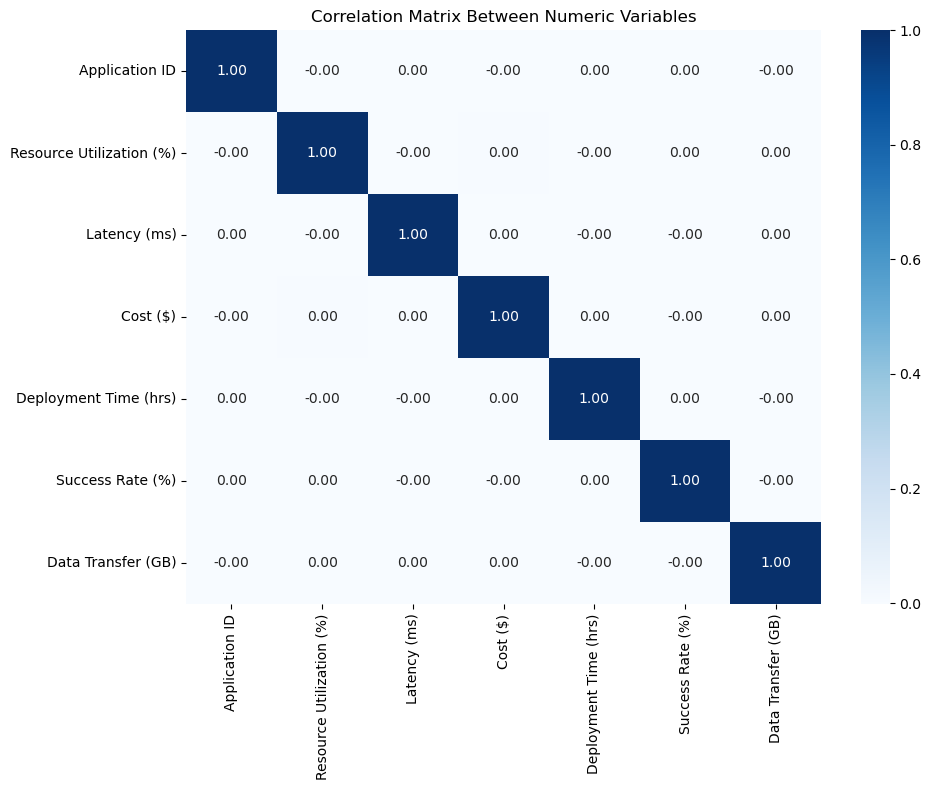

In [10]:
correlation = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Matrix Between Numeric Variables')
plt.tight_layout()
plt.show()

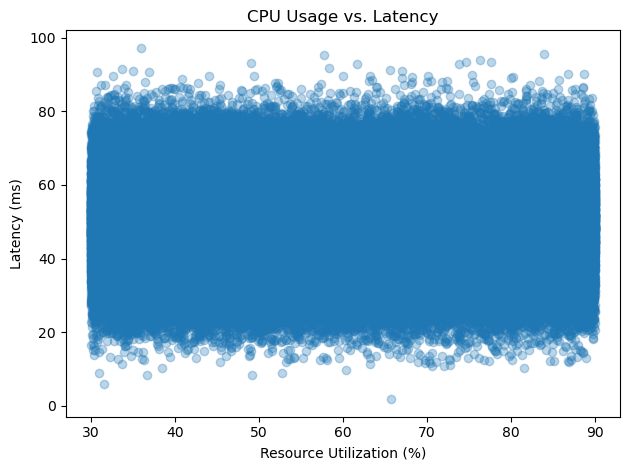

In [11]:
plt.scatter(df['Resource Utilization (%)'], df['Latency (ms)'], alpha=0.3)
plt.title('CPU Usage vs. Latency')
plt.xlabel('Resource Utilization (%)')
plt.ylabel('Latency (ms)')
plt.tight_layout()
plt.show()

In [12]:
from scipy import stats


prod_latency = df[df['Environment'] == 'Production']['Latency (ms)']
test_latency = df[df['Environment'] == 'Testing']['Latency (ms)']


t_stat, p_value = stats.ttest_ind(prod_latency, test_latency)


print(f'T-Statistic: {t_stat:.4f}, P-Value: {p_value:.4f}')
if p_value < 0.05:
    print('✅ Significant difference in latency between Production and Testing.')
else:
    print('❌ No significant difference in latency between Production and Testing.')


T-Statistic: 0.9239, P-Value: 0.3555
❌ No significant difference in latency between Production and Testing.


In [13]:

print("Average Latency:", df['Latency (ms)'].mean())


print("Average Cost:", df['Cost ($)'].mean())


df['Error Rate'] = 100 - df['Success Rate (%)']
print("Average Error Rate:", df['Error Rate'].mean())


print("Most Expensive Provider:", df.groupby('Cloud Provider')['Cost ($)'].mean().idxmax())


print("Environment with Highest Latency:", df.groupby('Environment')['Latency (ms)'].mean().idxmax())


Average Latency: 50.004140625
Average Cost: 2996.1171176
Average Error Rate: 5.255664775
Most Expensive Provider: AWS
Environment with Highest Latency: Production


In [ ]:
insight 

In [ ]:
Latency is consistent across environments, with average values near 50 ms. There is no significant difference between Production, Testing, and Development.

Deployment costs vary widely, with Google Cloud being the most expensive provider on average. This may be due to higher data transfer or service fees.

Success rates are high (around 95%), indicating reliable performance. The error rate is low and stable across all environments.

Cost is strongly influenced by deployment time and data transfer size, as shown by correlation and regression analysis.

CPU usage does not strongly affect latency, meaning performance bottlenecks may lie elsewhere (e.g., networking or service complexity).

 Recommendations:
Optimize data transfer and deployment time to reduce costs. These are the biggest drivers of overall expenses.

Consider cost-effective providers like IBM Cloud or Azure for services that do not require Google Cloud’s advanced capabilities.

Monitor microservices with high latency, even if average latency is low, to improve user experience.

No need to prioritize environment type changes to reduce latency, as environment type does not significantly affect it.

Explore non-linear models or include categorical variables (like Cloud Provider) in future cost prediction models to improve accuracy.